Approach used: https://arxiv.org/pdf/2108.10854 

In [ ]:
%pip install numpy matplotlib seaborn pylatexenc "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

In [ ]:
import math
import random
import numpy as np
import pandas as pd
import sys
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_qsphere

In [ ]:
N = 10
max_data_element = 10000

In [ ]:
dataset = [random.randint(0,max_data_element) for _ in range(N)]
print("Dataset: ", dataset)

Dataset:  [7323, 7791, 9200, 2647, 6143, 206, 3073, 6274, 6011, 4201]


STEP 1: Develop the AAE layers using PQC for dataset encoding

In [ ]:
class approximateAmplitudeEncoder:
  def init(self, dataset, depth):
    self.depth = depth
    self.N = len(dataset)
    self.n = math.ceil(math.log2(self.N))

    dimension = 2 ** self.n

    dataset = np.pad(
        dataset,
        (0, dimension - self.N),
        mode="constant"
    )

    print("Number of qubits:", self.n)
    print("Quantum state dimension:", dimension)

    print("Padded dataset:")
    print(dataset)

    plt.figure(figsize=(7, 4))
    sns.histplot(data=dataset, stat="probability", kde=True)
    plt.title("Padded Dataset")
    plt.xlabel("Amplitude")
    plt.ylabel("Probability")
    plt.show()

    num_parameters = self.depth * self.n * 2

    print("\nNumber of qubits:", self.n)
    print("PQC depth:", self.depth)
    print("Number of trainable parameters:", num_parameters)

    self.target = dataset / np.linalg.norm(dataset)

    print("\nNormalized target amplitudes:")
    print(self.target)

    print("\nNormalization check:")
    print(np.sum(self.target ** 2))

    plt.figure(figsize=(7, 4))
    sns.histplot(data=self.target, stat="probability", kde=True)
    plt.title("Normalized Target Amplitudes")
    plt.xlabel("Amplitude")
    plt.ylabel("Probability")
    plt.show()

    # Initial parameters
    np.random.seed(42)

    num_parameters = self.depth * self.n * 2

    initial_parameters = np.random.uniform(
        -np.pi,
        np.pi,
        num_parameters
    )

    print("\nInitial parameters:")
    print(initial_parameters)

    print("\nInitial cost:")
    print(self.cost_function(initial_parameters))

    return initial_parameters

  def create_pqc(self, parameters):
    qc = QuantumCircuit(self.n)
    parameter_index = 0

    for layer in range(self.depth):

        # Single-qubit rotations
        for q in range(self.n):

            theta = parameters[parameter_index]
            phi = parameters[parameter_index + 1]

            qc.ry(theta, q)
            qc.rz(phi, q)

            parameter_index += 2

        # Entangling layer
        for q in range(self.n - 1):
            qc.cx(q, q + 1)

    return qc

  def cost_function(self, parameters):
    qc = self.create_pqc(parameters)
    state = Statevector.from_instruction(qc)

    overlap = np.vdot(self.target, state.data)

    fidelity = np.abs(overlap) ** 2

    cost = 1 - fidelity

    return cost

  def run_pqc(self, dataset, depth):
    initial_parameters = self.init(dataset, depth)

    result = minimize(
        self.cost_function,
        initial_parameters,
        method="COBYLA",
        options={
            "maxiter": 1000
        }
    )

    trained_parameters = result.x

    print("\nOptimization finished.")
    print("Final cost:", result.fun)
    print("Final fidelity:", 1 - result.fun)

    print("\nTrained parameters:")
    print(trained_parameters)

    # Create trained circuit
    trained_qc = self.create_pqc(trained_parameters)

    print("\nFinal trained circuit:")
    display(trained_qc.draw("mpl"))

    # Final state
    final_state = Statevector.from_instruction(trained_qc)

    print("\nTarget amplitudes:")
    print(self.target)

    print("\nPQC amplitudes:")
    print(np.real_if_close(final_state.data))

    # Fidelity
    final_overlap = np.vdot(
        self.target,
        final_state.data
    )

    final_fidelity = np.abs(final_overlap) ** 2

    print("\nFinal fidelity:")
    print(final_fidelity)

    plt.figure(figsize=(8, 5))
    plt.plot(np.abs(self.target) ** 2, 'o-', label='Target')
    plt.plot(np.abs(final_state.data) ** 2, 's-', label='PQC')

    plt.xlabel("Basis state")
    plt.ylabel("Probability")
    plt.title(f"Target vs PQC Probability Distribution\nFidelity = {final_fidelity:.4f}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return trained_parameters

STEP 2: Run Grover Search algorithm with the AAE layers

In [ ]:
class groverSearch:
  def initialize(self): # O(N)
    # quantum state = 1/root_N (summation_(N) |i>|0>|->)

    print("\nTotal qubits: ", self.total_qubits)
    qc = QuantumCircuit(self.total_qubits)

    print("Index qubits: ", self.index_q)

    # handling dataset of arbitrary size
    amplitudes = np.zeros(2**self.n, dtype=complex) # O(N)

    for i in range(2**self.n):  # O(N)
        amplitudes[i] = 1 / np.sqrt(2**self.n)

    state = Statevector(amplitudes)

    # PQC prepares the initial index state
    self.AAE = approximateAmplitudeEncoder()
    self.aae_trained_parameters = self.AAE.run_pqc(dataset, depth=3)

    self.pqc = self.AAE.create_pqc(self.aae_trained_parameters)
    qc.compose(self.pqc, qubits=self.index_q, inplace=True)

    # Prepare ancilla |->
    qc.x(self.ancilla)
    qc.h(self.ancilla)

    qc.barrier()

    return qc

  def mark_target(self, qc):  # O(d)
    # 1/root_N summation_(N) ( |i>|d>|-> ) --mark_target -->
    # 1/root_N ( -summation_(M) |i>|T>|-> + summation_(N-M) ( |i>|d>|-> ) )

    zero_controls = []

    for bit in range(self.d):
      if ((target >> bit) & 1) == 0:
          qc.x(self.data_q[bit])
          zero_controls.append(self.data_q[bit])

    qc.mcx(self.data_q, self.ancilla) # |-> --> -|-> (phase kickback for target)

    for q in zero_controls:
      qc.x(q)

    return qc

  def oracle(self): # O(N.(logN+d))
    qc = QuantumCircuit(self.total_qubits)

    qc.compose(self.pqc, qubits=self.index_q, inplace=True)
    qc.barrier()

    self.mark_target(qc) # O(d)
    qc.barrier()

    qc.compose(self.pqc, qubits=self.index_q, inplace=True)
    qc.barrier()

    return qc

  def diffuser(self): # O(1)
    # D = 2∣s⟩⟨s∣ − I
    # D∣ψ⟩ = ∑_i​ (2.mean − a_i​)∣i⟩

    qc = QuantumCircuit(self.n)

    qc.h(self.index_q) # makes the amplitude of |00...0> twice the mean of all the amplitudes
    qc.x(self.index_q) # |00...0> --> |11...1>

    if self.n == 1:  # only one qubit
        qc.z(0) # change the phase of the one qubit

    else:
        # H.MCX.H = MCZ (controlled phase flip)
        qc.h(self.n - 1) # qubit[n-1] is last index qubit
        qc.mcx(list(range(self.n - 1)), self.n - 1) # |11...1> --> - |11...1>
        qc.h(self.n - 1)

    qc.x(self.index_q) # |11...1> --> |00...0> has -2.mean amplitude
    qc.h(self.index_q) # inversion about mean: every amplitude = 2.mean - amplitude

    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10    # shows maximum of 10 locators on the x-axis of the chart (decreases overcrowding)

    state = Statevector.from_instruction(qc)
    # display(plot_state_qsphere(state))
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()}  # convert binary index to decimal

    print(f"{text}: ", probs_dict)
    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))
    display(plot)

  def run(self, dataset, target, no_of_shots=10):
    self.N = len(dataset)
    self.n = math.ceil(math.log2(self.N))

    # PROBLEM: finding max O(N) and as d increases so does the number of qubits and the complexity of the circuit.
    # it can be 32 bit or 64 integer depending on the system and hence would require as many qubits
    self.d = math.ceil(math.log2(max(dataset) + 1))

    self.index_q = list(range(self.n))
    self.data_q = list(range(self.n, self.n + self.d))
    self.ancilla = self.n + self.d
    self.total_qubits = self.n + self.d + 1

    print("N = ", self.N)
    print("n = ", self.n)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Ancilla = ", self.ancilla)
    print("Total no of qubits = ", self.total_qubits)

    theta = math.asin(math.sqrt(M / self.N)) + sys.float_info.epsilon
    no_of_iter = max(1, round(((math.pi / 4) * math.sqrt(N / M)) - 0.5))

    print(f"\nTheta: {theta}")
    print(f"Total no of iterations: {no_of_iter}")

    index_qubits = QuantumRegister(self.n, name="index")
    data_qubits = QuantumRegister(self.d, name="data")
    ancilla_qubit = QuantumRegister(1, name="ancilla")
    classical_register = ClassicalRegister(self.n, name="index_result")
    qc = QuantumCircuit(index_qubits, data_qubits, ancilla_qubit, classical_register)

    init = self.initialize() # O(N)
    qc.compose(init,inplace=True)
    self.visualize(qc, "Initial state")

    for iteration in range(no_of_iter):     # O(root_N * (N.(logN+d))) ≈ O(N^(3/2).logN)

        print(f"\nGROVER ITERATION {iteration+1}")

        print("\nORACLE")
        oracle_circuit = self.oracle()   # O(N.(logN+d))
        qc.compose(oracle_circuit, qubits=self.index_q + self.data_q + [self.ancilla],inplace=True)
        state_oracle = Statevector.from_instruction(qc)
        probs_dict = state_oracle.probabilities_dict(qargs=self.index_q)
        probs_dict = {int(k, 2): v for k, v in probs_dict.items()}
        self.visualize(qc, "Oracle output")

        print("\nDIFFUSER")
        diffuser_circuit = self.diffuser()   # O(1)
        qc.compose(diffuser_circuit, qubits=self.index_q, inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()
    self.qc.measure(self.index_q, range(self.n))

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)
    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size   (N):", self.N)
    print("Index qubits   (n):", len(self.index_q))
    print("Data qubits    (d):", len(self.data_q))
    print("Ancilla           :", 1)
    print("Classical bits (n):", len(self.index_q))

    print("\nCIRCUIT ANALYSIS")

    print("Total qubits                                    :", self.qc.num_qubits)
    print("Circuit width (quantum bits + classical bits)   :", self.qc.width())
    print("Circuit size (total number of operations/gates) :", self.qc.size())
    print("Circuit depth/layers                            :", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

In [ ]:
target = random.choice(dataset)
target

6274

In [ ]:
# actual answer through classical search
target_indices = [
    i for i, value in enumerate(dataset)
    if value == target
]
M = len(target_indices)
target_indices

[7]

N =  10
n =  4
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Ancilla =  18
Total no of qubits =  19

Theta: 0.3217505543966424
Total no of iterations: 2

Total qubits:  19
Index qubits:  [0, 1, 2, 3]
Number of qubits: 4
Quantum state dimension: 16
Padded dataset:
[7323 7791 9200 2647 6143  206 3073 6274 6011 4201    0    0    0    0
    0    0]


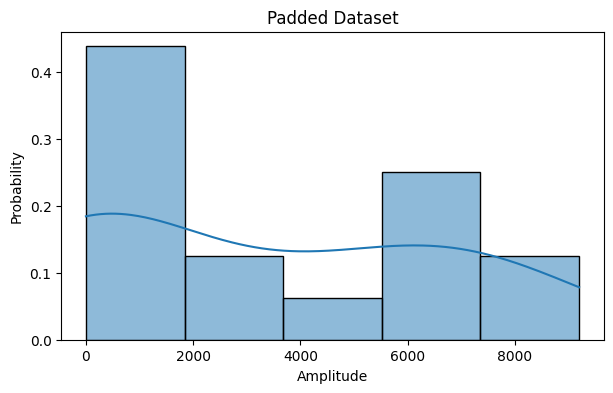


Number of qubits: 4
PQC depth: 3
Number of trainable parameters: 24

Normalized target amplitudes:
[0.39349452 0.41864206 0.49435335 0.14223406 0.33008833 0.01106922
 0.16512477 0.33712749 0.32299544 0.22573679 0.         0.
 0.         0.         0.         0.        ]

Normalization check:
1.0


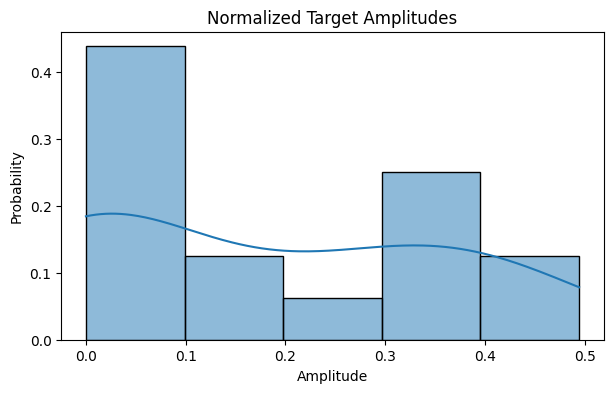


Initial parameters:
[-0.78828768  2.83192151  1.45766093  0.61988954 -2.16129862 -2.16145018
 -2.77664256  2.30075258  0.63532436  1.30735856 -3.01225646  2.95253068
  2.08879872 -1.80742667 -1.99915269 -1.98922813 -1.22998226  0.15554925
 -0.42760206 -1.311746    0.70279246 -2.26512688 -1.30599369 -0.8396733 ]

Initial cost:
0.967046916151195

Optimization finished.
Final cost: 0.0802991427902181
Final fidelity: 0.9197008572097819

Trained parameters:
[ 1.55645912  3.40672217  2.68243993  0.51159798 -2.49937412 -0.98312071
 -1.06852199  3.28584162  1.77374806  1.76328735 -3.32247548  4.19762614
  3.54453563 -1.59603511 -0.49032578 -1.19547631  1.5112588   0.4552859
 -0.22998999  0.35704096  2.21585373 -3.10044352 -0.35889699 -1.15043849]

Final trained circuit:


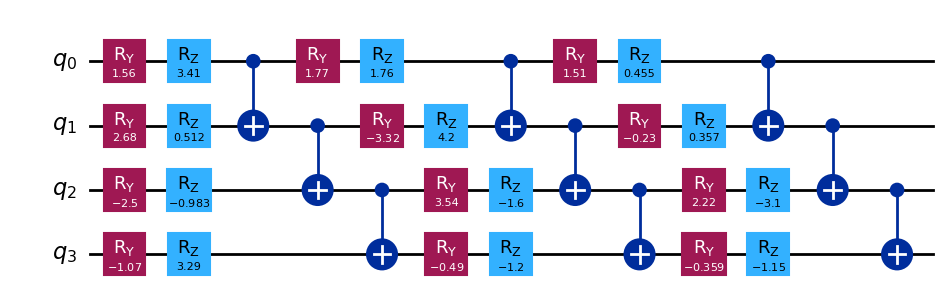


Target amplitudes:
[0.39349452 0.41864206 0.49435335 0.14223406 0.33008833 0.01106922
 0.16512477 0.33712749 0.32299544 0.22573679 0.         0.
 0.         0.         0.         0.        ]

PQC amplitudes:
[ 0.24446586+0.15111862j  0.30906671+0.1515801j   0.4806653 +0.17698296j
  0.17173459+0.01586584j  0.32601887+0.21780972j  0.09044862+0.09323207j
  0.18104132+0.09411786j  0.29801691+0.11052174j  0.32497444+0.06134493j
  0.19716495+0.14126552j -0.04198743-0.08234747j  0.03145698+0.01062511j
 -0.03237204+0.03627393j -0.01725925-0.01539112j  0.04171547-0.02339532j
  0.02222943+0.10000112j]

Final fidelity:
0.9197008572097819


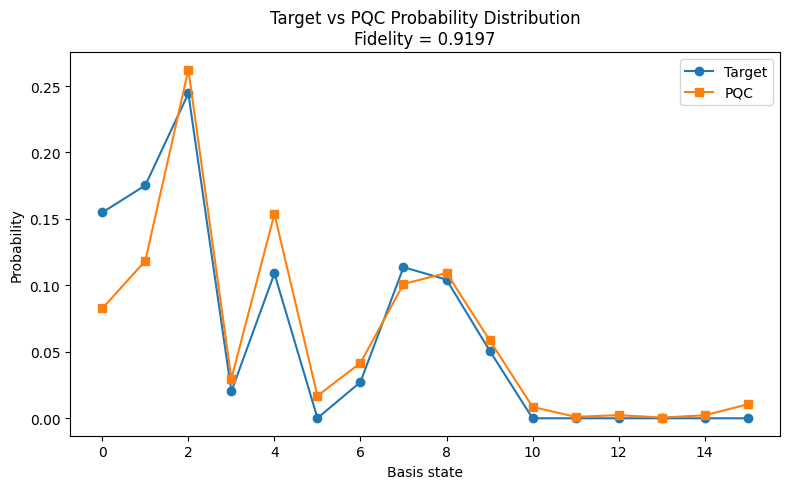

Initial state:  {0: np.float64(0.9999999999999998)}


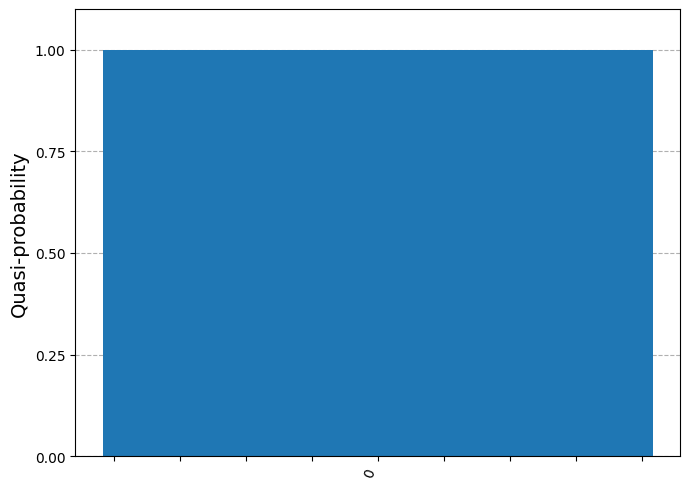


GROVER ITERATION 1

ORACLE
Oracle output:  {0: np.float64(0.018350492257804142), 1: np.float64(0.08242001381110128), 2: np.float64(0.21980216398084998), 3: np.float64(0.042364609029478945), 4: np.float64(0.04041163905354649), 5: np.float64(0.014609554804389965), 6: np.float64(0.03941366735337767), 7: np.float64(0.022561689936399502), 8: np.float64(0.0809576348371788), 9: np.float64(0.01827421837251987), 10: np.float64(0.038328881312484506), 11: np.float64(0.17199336360533685), 12: np.float64(0.06181284931979752), 13: np.float64(0.07676357915802887), 14: np.float64(0.013708234778287216), 15: np.float64(0.05822740838919571)}


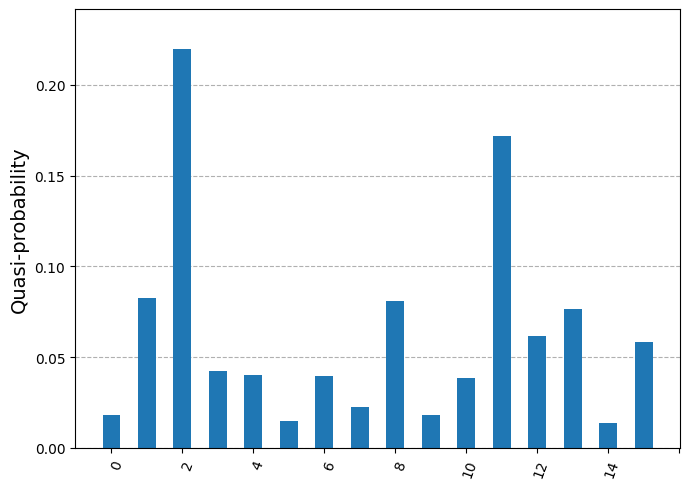


DIFFUSER
Diffuser output:  {0: np.float64(0.0205352937471231), 1: np.float64(0.0944504985619112), 2: np.float64(0.19284791471940954), 3: np.float64(0.05958192602008201), 4: np.float64(0.0310516069451365), 5: np.float64(0.01896111301079113), 6: np.float64(0.025050398007452547), 7: np.float64(0.040054659920797986), 8: np.float64(0.059302909371454327), 9: np.float64(0.033166460278322596), 10: np.float64(0.04508178868815407), 11: np.float64(0.2071868265168391), 12: np.float64(0.03955825806729281), 13: np.float64(0.05165727305807423), 14: np.float64(0.005915095261110869), 15: np.float64(0.07559797782582289)}


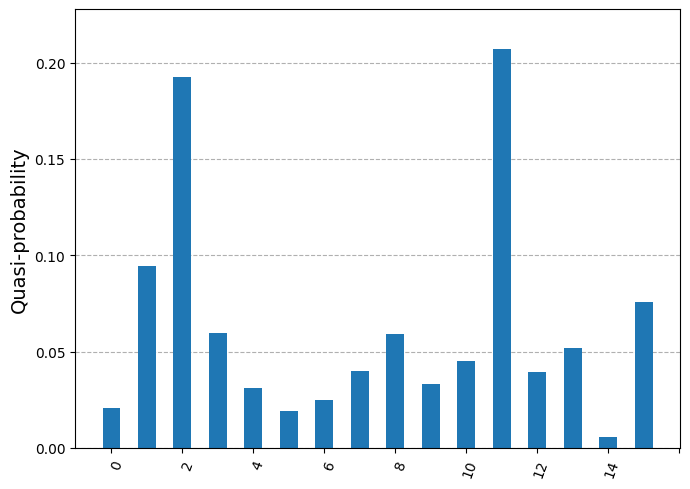


GROVER ITERATION 2

ORACLE
Oracle output:  {0: np.float64(0.09844539358103367), 1: np.float64(0.04847738390757812), 2: np.float64(0.2541091022051901), 3: np.float64(0.007675666874547191), 4: np.float64(0.06258073227491755), 5: np.float64(0.1000310279902173), 6: np.float64(0.05157497300854919), 7: np.float64(0.15217790990151572), 8: np.float64(0.02442235644925321), 9: np.float64(0.1370168721744975), 10: np.float64(0.001915014619654484), 11: np.float64(0.005679869105259942), 12: np.float64(0.004915112713614904), 13: np.float64(0.021511776228134657), 14: np.float64(0.008356972476290778), 15: np.float64(0.02110983648929926)}


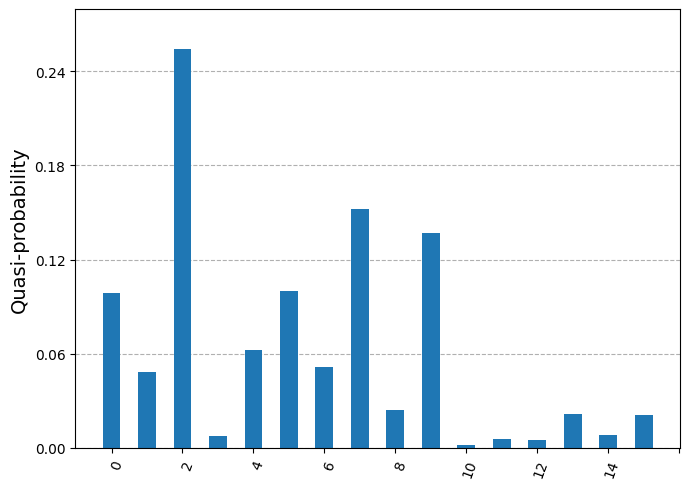


DIFFUSER
Diffuser output:  {0: np.float64(0.1310509242055546), 1: np.float64(0.13546566862145631), 2: np.float64(0.14698601233080746), 3: np.float64(0.010718414258129), 4: np.float64(0.056671391723191536), 5: np.float64(0.04790955358421074), 6: np.float64(0.10389557143605152), 7: np.float64(0.07328922145530345), 8: np.float64(0.03128636362964989), 9: np.float64(0.04307172529164258), 10: np.float64(0.015449362988765534), 11: np.float64(0.05652169301679879), 12: np.float64(0.047097665650559936), 13: np.float64(0.09397672429894777), 14: np.float64(0.006023881218647744), 15: np.float64(0.0005858262898345975)}


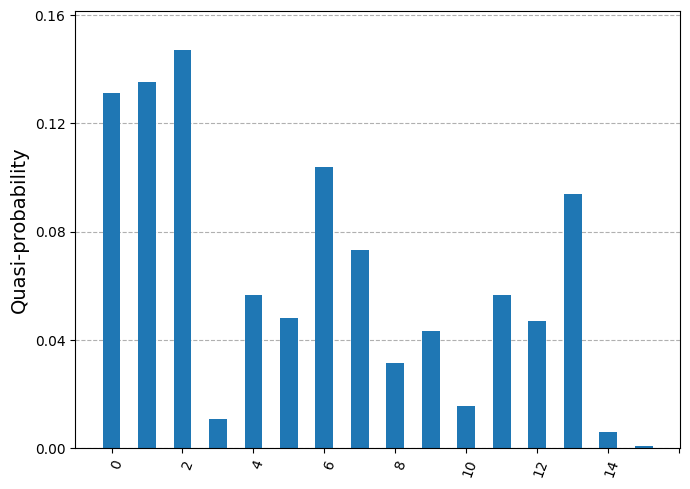


FINAL MEASUREMENT

Index measurement results for (10) shots:
{'0100': 1, '0001': 1, '1011': 1, '1101': 1, '0000': 2, '1100': 4}


In [ ]:
GS = groverSearch()
GS.run(dataset, target)

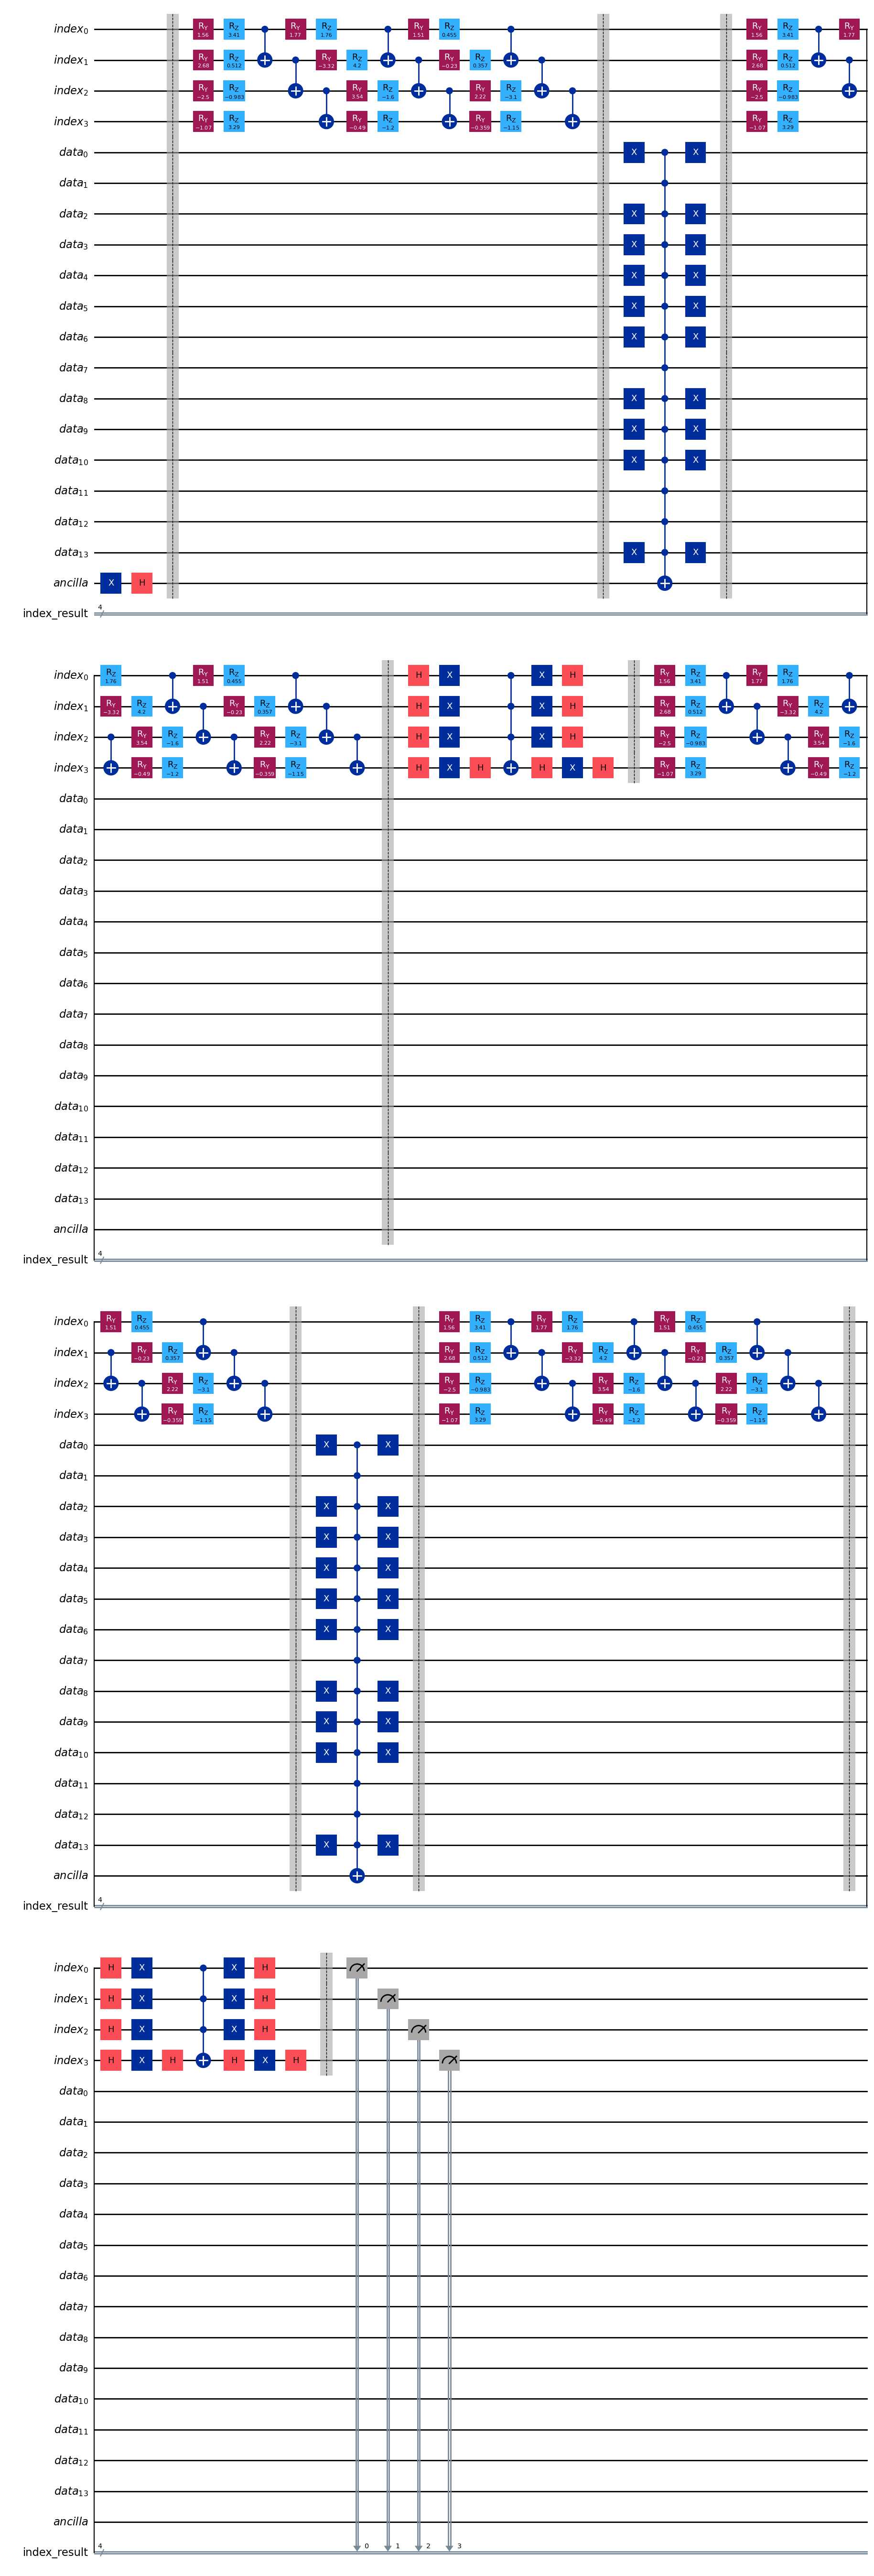

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()

REGISTER ANALYSIS
Dataset size   (N): 10
Index qubits   (n): 4
Data qubits    (d): 14
Ancilla           : 1
Classical bits (n): 4

CIRCUIT ANALYSIS
Total qubits                                    : 19
Circuit width (quantum bits + classical bits)   : 23
Circuit size (total number of operations/gates) : 218
Circuit depth/layers                            : 75

OPERATION COUNT
OrderedDict({'x': 57, 'ry': 48, 'rz': 48, 'cx': 36, 'h': 21, 'barrier': 9, 'mcx': 4, 'measure': 4})
